In [1]:
%pip install numpy matplotlib nbconvert scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Ballistic Tracking with Kalman Filters

This notebook demonstrates progressively more capable Kalman filter variants for tracking a projectile in flight.

## The problem

A sensor (radar, lidar, GPS) measures the **position** of a projectile at discrete times, corrupted by noise.  
Our goal is to recover the full state — position, velocity, and acceleration — from these noisy measurements.

We start with the simplest possible model (1D linear) and work up to a full 3D nonlinear EKF that accounts for gravity and drag.

| Section | Model | Engine | Notes |
|---|---|---|---|
| 1 | `BallisticLinearModel` (1D) | Linear KF | Constant-acceleration, single axis |
| 2 | `BallisticLinearModel` × N runs | Linear KF + `KalmanRecordCollection` | Ensemble / variance analysis |
| 3 | `BallisticLinearModel` × 3 axes | Linear KF (composite) | Three independent axes via `CompositeKalmanModel` |
| 4 | `BallisticModel` (3D EKF) | Extended KF | Nonlinear gravity + drag, coupled axes |
| 5 | `BallisticDopplerModel` | EKF | Multi-modal: position + radial Doppler velocity |
| 6 | `BallisticAugmentedModel` | EKF | Augmented state: c_drag estimated online |
| 7 | `BallisticModel` | UKF vs EKF | Sigma-point filter comparison |
| 8 | `BallisticModel` | EKF + NaN masking | GPS at 10 Hz fused into 128 Hz prediction loop |

---

**Key parameters:**
- `measurement_uncertainty` (`r`) — standard deviation of position sensor noise [m]
- `process_uncertainty` (`q`) — standard deviation of unmodelled acceleration [m/s²/√step]
- `smooth=True` — runs the **Rauch-Tung-Striebel (RTS) backward smoother** after the forward filter, reducing lag and improving accuracy

## The state-space model & terminology

A **Kalman filter** estimates a hidden **state** $x$ (what we care about) from noisy
**measurements** $z$, by alternating two steps every sample:

- **predict** — push the state forward in time using the system *dynamics*;
- **update** — correct the prediction using the latest measurement.

Dynamics and sensor are written as a **linear state-space model**:

$$\underbrace{\dot{x}(t) = A\,x + B\,u + L\,w}_{\text{dynamics (continuous)}}
\qquad
\underbrace{z = H\,x + v}_{\text{observation}}$$

The code runs in discrete time with step $\Delta t = 1/f_s$:

$$x_{k+1} = F\,x_k + B\,u_k + w_k,\qquad z_k = H\,x_k + v_k,\qquad F = e^{A\,\Delta t}.$$

| symbol | name | meaning |
|---|---|---|
| $x$ | **state vector** | the hidden quantities we track |
| $F$ | **state-transition** | how the state evolves one step ($F=e^{A\Delta t}$) |
| $H$ | **observation matrix** | maps state → what the sensor measures |
| $Q$ | **process-noise covariance** | trust in the *model* (un-modeled forces); larger $Q$ ⇒ trust the model less |
| $R$ | **measurement-noise covariance** | trust in the *sensor*; larger $R$ ⇒ trust measurements less |
| $w,v$ | process / measurement noise | zero-mean Gaussian, $w\sim\mathcal N(0,Q)$, $v\sim\mathcal N(0,R)$ |
| $u$ | **control input** | known external forcing (here: thrust) |

When the dynamics are **nonlinear**, $\dot x = f(x,u)$, the **Extended KF (EKF)** linearises
them on the fly: $F=\partial f/\partial x$ at the current estimate (its **Jacobian**).

### This notebook's models

**1 — Linear (constant-acceleration)**, state $x=[p,v,a]^\top$:
$$\dot p = v,\quad \dot v = a,\quad \dot a = w
\;\Rightarrow\;
A=\begin{bmatrix}0&1&0\\0&0&1\\0&0&0\end{bmatrix},\;
H=[\,1\;0\;0\,],\;R=\sigma_{\text{meas}}^2 .$$

**2 — Nonlinear ballistic (EKF)**, per axis $[p,v,a]$ in 3-D:
$$\dot p = v,\qquad
\dot v = \underbrace{-g\,\hat z\;\text{or}\;-\tfrac{GM}{\lVert p\rVert^{3}}\,p}_{\text{gravity}}
\;\underbrace{-\tfrac{c_d}{m}\lVert v\rVert\,v}_{\text{drag}}
\;+\;\underbrace{u/m}_{\text{thrust}}\;+\;w,$$
with $z=p$, $F=\partial f/\partial x$ (numerical Jacobian), $R=\sigma_{\text{meas}}^2 I_3$.

## Section 1 — 1D Linear Kalman Filter

We start with the simplest case: tracking a body moving along **one axis** from noisy position
readings. Even here the Kalman filter does something remarkable — it recovers the **velocity and
acceleration**, which were never measured, from a stream of noisy positions alone.

**The idea in one line.** Each time step the filter (1) *predicts* the next state from a motion
model, then (2) *updates* that prediction with the new measurement, weighting the two by how much it
trusts each.

**Key terms**
- **State vector** $\mathbf{x}=[z,\dot z,\ddot z]^\top$ — the hidden quantities we estimate
  (position, velocity, acceleration).
- **Transition matrix $F$** — encodes the motion model; here *constant acceleration*.
- **Measurement matrix $H$** — maps the state to what the sensor sees (position only).
- **Process noise $Q$** — how much we distrust the model (un-modelled jerk/forces).
- **Measurement noise $R=r^2$** — how noisy the sensor is.

$$F = \begin{pmatrix} 1 & \Delta t & \tfrac{1}{2}\Delta t^2 \\ 0 & 1 & \Delta t \\ 0 & 0 & 1 \end{pmatrix},\qquad
H = \begin{pmatrix} 1 & 0 & 0 \end{pmatrix}$$

**The $Q$–$R$ tug-of-war.** Large $r$ (noisy sensor) → the filter trusts the model → a smoother but
laggier estimate. Large $q$ (uncertain model) → it trusts measurements → responsive but noisier.
Tuning this balance is the heart of applying a Kalman filter.

**RTS smoother.** The forward filter is *causal* — at time $k$ it has only seen measurements up to
$k$. The **Rauch–Tung–Striebel (RTS) smoother** adds a backward pass that also uses *future*
measurements, improving every estimate at the cost of latency — ideal for offline/batch processing.

*What to look for:* the filtered estimate tracks the truth through the noise, and the smoother
(green) is tighter still, especially early on where the forward filter is still converging.

In [2]:
from kalman.apps.ballistics import BallisticLinearModel

# Initialize the model. Gravity is KNOWN exactly, so pin z̈ with acc_uncertainty=0
# (zero initial variance on acceleration; with Q[2,2]=0 it stays at -9.81 for all time).
bulletbill = BallisticLinearModel("Z", sample_rate=256,
                                  measurement_uncertainty=500,
                                  process_uncertainty=1,
                                  acc_uncertainty=0,        # known gravity → fixed z̈
                                  random_seed=42)
bulletbill.initial_state([0, 100, -9.81])   # [z, ż, z̈] at t=0
bulletbill.print()

# Sample truth + noisy measurements, then filter (with RTS smoothing)
chrono.restart()
sample = bulletbill.sample(8)            # 8 seconds of data
chrono.lap("Sampling completed")
record = bulletbill.filter(sample, smooth=True, reset=True)
chrono.lap("Filtering completed")
chrono.summary()

BallisticLinearModel(LinearKalmanModel) @ fs=256Hz
    Ballistic State Model (v1.3)
        Linear constant-acceleration toy model; position
        measured.
    Dimensions Summary:
        State Vector....................................: 3 dims (BallisticState<POSITION, SPEED, ACCELERATION>)
        Observation.....................................: 1 dim  (BallisticObservable<POSITION>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 3x1 dims
        State Covariance (P0)...........................: 3x3 dims

Chrono summary:
 1. Sampling completed: 0.008898s (ΔT=0.008898s)
 2. Filtering completed: 0.114422s (ΔT=0.105524s)

==> Total elapsed: 0.114439s



### Interactive 4-panel dashboard (joint time slider)

A single time slider drives **all four pads at once** — position, speed, acceleration, and the measurement-error distribution growing toward its Gaussian. This is the unified `plot(interactive=True, …)` entry point: pass a list of `component`s (one pad each), `error=True` to append the histogram, and `sample=` to overlay truth and measurements with the standard **Measured / Ideal / True / Smoothed** colors.

In [ ]:
# The model's interactive signature figure: one joint slider, four pads
# (position / speed / acceleration + measurement-error histogram).
# Reuses `record` / `sample` from the cell above (run it first).
bulletbill.plot(record, sample=sample, interactive=True)

### Interpreting the plots

- **Position** — filter output closely tracks the truth even through noisy measurements.  The smoother (dashed) is tighter because it uses future data.
- **Speed** — never directly measured; reconstructed from position history by the filter.  Smoother eliminates startup transient.
- **Acceleration** — latent state; the model assumes constant $\ddot{z} = -9.81$ m/s².  Process noise $q$ allows slow drift.
- **Error histogram** — residuals should be approximately zero-mean and Gaussian. Large tails indicate model mismatch or under-estimated $R$.

> **Try it:** increase `measurement_uncertainty` to 2000 — observe how the filter uncertainty widens but the smoother still recovers well.

## Section 2 — Ensemble Analysis with `KalmanRecordCollection`

A single filter run shows **one** random draw of the measurement noise — it might look great, or
unlucky, by chance. To judge a filter honestly you must look at its **behaviour over many runs**.

**Key terms**
- **Monte-Carlo ensemble** — repeat the experiment $N$ times with independent noise and aggregate
  the results.
- **Filter consistency** — a filter is *consistent* when its reported uncertainty matches its actual
  errors: the truth should fall inside the $\pm2\sigma$ band it predicts about **95%** of the time.
  Over-confident filters (errors leak outside the band) are dangerous; over-conservative ones waste
  information.
- **Empirical vs predicted covariance** — the spread of the ensemble (empirical) should match the
  covariance $P$ the filter itself computes (predicted).

`KalmanRecordCollection` runs and overlays the trials, so you can see the error cloud, the
$\pm2\sigma$ envelope, and compare parameter settings side by side.

*What to look for:* the ensemble spread sits inside the predicted band — confirming the filter's
self-reported confidence is trustworthy.

Run 2/2: 0.189414s
KalmanRecordCollection with 2 records: 
  0: KalmanRecord(N=2048, n=3, m=1, flavor=smoothed, model=Ballistic State Model)
  1: KalmanRecord(N=2048, n=3, m=1, flavor=smoothed, model=Ballistic State Model)


(<Axes: title={'center': 'Ballistic State Model'}, xlabel='Time (s)', ylabel='Position Z'>,
 <Axes: title={'center': 'Ballistic State Model'}, xlabel='Time (s)', ylabel='Position Z'>)

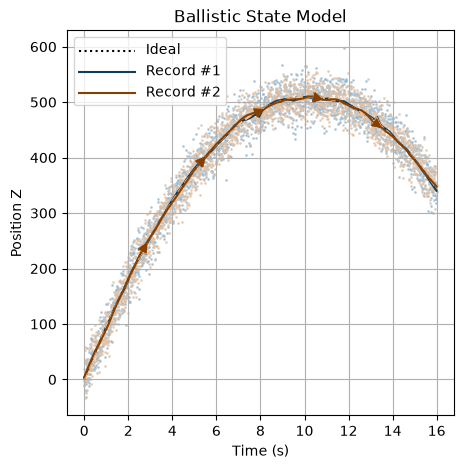

In [4]:
from kalman.apps.ballistics import BallisticLinearModel
from kalman.framework.io.collection import KalmanRecordCollection

bulletbill = BallisticLinearModel("Z", sample_rate=128,
                                  measurement_uncertainty=500,
                                  process_uncertainty=0.5)
bulletbill.initial_state([0, 100, -9.81])

chrono.restart()

N = 2
samples, records = [], []
for i in range(N):
    samples.append(bulletbill.sample(16))
    records.append(bulletbill.filter(samples[-1], smooth=True, reset=True))
    if i % 4 == 0 or i == N - 1:
        print(chrono.lap(f"Run {i+1}/{N}"), end="\r" if i < N - 1 else "\n")

collection = KalmanRecordCollection(records)
collection.print()

# Overlay all runs on a single plot
collection.plot(samples=samples, component=bulletbill.states.POSITION)

### Interpreting the ensemble plot

Each line is an independent run; the spread reflects the effect of measurement noise on the filtered trajectory.  
A well-calibrated filter should show scatter consistent with the predicted covariance $P_k$ — **not** systematically tighter or wider.

If the scatter is wider than the $\pm 2\sigma$ bands → $R$ (sensor noise) is under-estimated.  
If all runs are nearly identical → $R$ may be over-estimated, and the filter overly trusts the model.

## Section 3 — 3D Composite Linear KF (Independent Axes)

Real motion is three-dimensional. The simplest 3-D filter treats the X, Y, Z axes as **independent**
1-D trackers running in parallel — valid whenever nothing couples the axes.

**Key terms**
- **Composite model** — `CompositeKalmanModel` stacks several sub-models into one larger model,
  assembling **block-diagonal** $F, H, Q, R$ automatically.
- **Block-diagonal covariance** — the zero off-diagonal blocks mean the axes share no information;
  each evolves entirely on its own.
- **Axis-major layout** — the state groups all components of one axis together:
  `x = [px,vx,ax, py,vy,ay, pz,vz,az]`.

This decoupling is *exact* only when each axis has constant acceleration and there is **no coupling
force** — no central gravity, no speed-dependent drag (e.g. short-range, high-speed flight).
Section 4 shows exactly what breaks when that assumption fails.

The `dim` plot argument selects the spatial axis (0 = X, 1 = Y, 2 = Z).

KalmanRecord:
    Summary:
        Attached Model....................................: Composite Kalman Model (v1.0)
        Description.......................................: float64
        Samples...........................................: 2048 data points
        Sample Rate.......................................: 128 Hz
        State Dimension (n)...............................: 9D
        Observation Dimension (m).........................: 3D
        Flavor............................................: posterior
        Start Time........................................: 0s
        Duration..........................................: 16s
    Dimensions & Data Quality:
        Time (s) .........................................: [0s .. 16s[
        Measurements (zk) ................................: 2048x(3)
        State Vector (xk) ................................: 2048x(9)
        State Covariance (Pk) ............................: 2048x(9x9)

    State Vector Averages (per dime

Chrono summary:
 1. Model initialized: 0.000487s (ΔT=0.000487s)
 2. Sampling completed: 0.172883s (ΔT=0.172396s)
 3. Filtering completed: 0.523513s (ΔT=0.350630s)
 4. Position plots completed: 1.052708s (ΔT=0.529195s)
 5. Speed plots completed: 1.579000s (ΔT=0.526292s)
 6. Correlation plot completed: 1.757873s (ΔT=0.178873s)

==> Total elapsed: 1.757890s



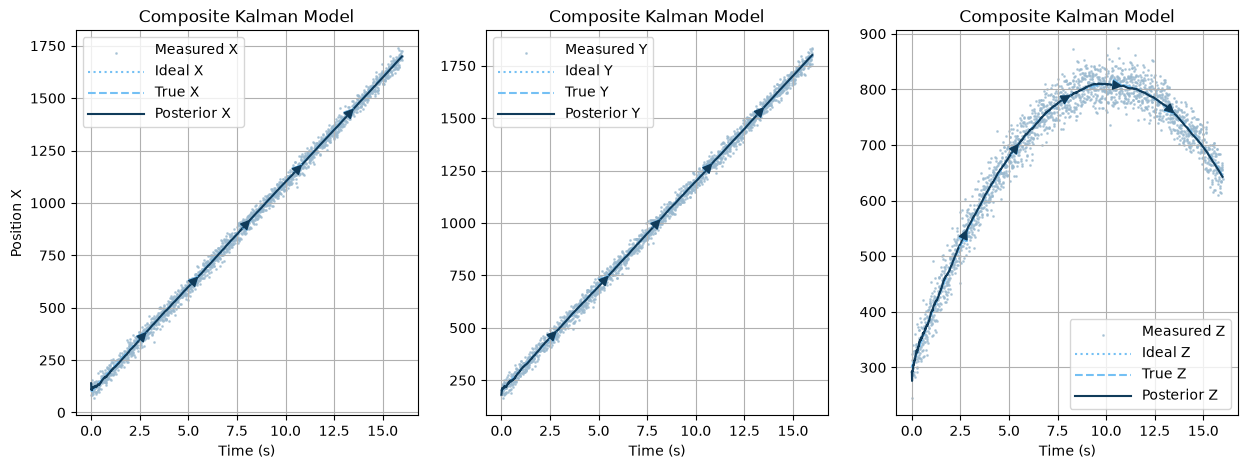

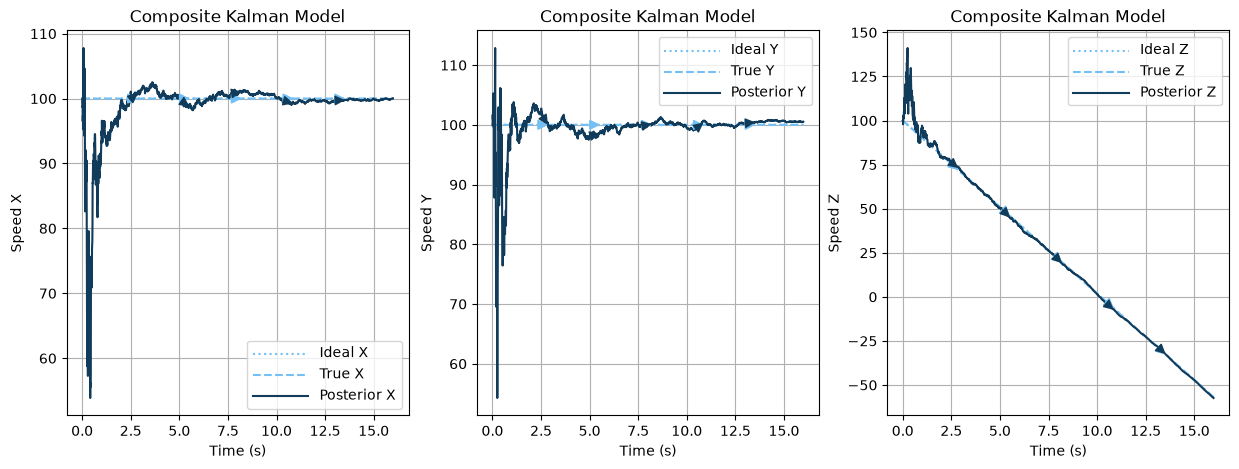

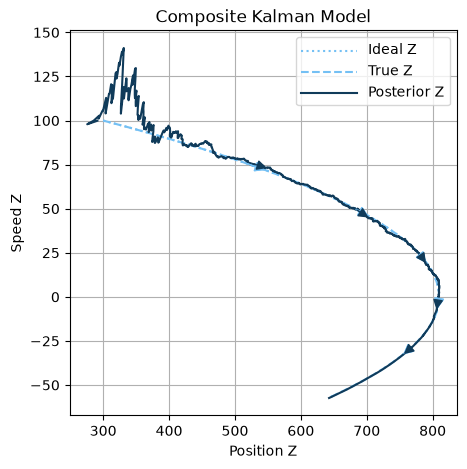

In [5]:
chrono.restart()

from kalman.apps.ballistics import BallisticLinearModel
from kalman.framework.models.composite import CompositeKalmanModel

bulletbill = CompositeKalmanModel(
    BallisticLinearModel("X", sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42),
    BallisticLinearModel("Y", sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42),
    BallisticLinearModel("Z", sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42)
)
bulletbill.initial_state([
    [100, 100,     0],   # X: [px, vx, ax]
    [200, 100,     0],   # Y: [py, vy, ay]
    [300, 100, -9.81]    # Z: [pz, vz, az]
])
chrono.lap("Model initialized")

sample = bulletbill.sample(16)
chrono.lap("Sampling completed")

record = bulletbill.filter(sample.zk, smooth=False, reset=True)
record.print()
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
from kalman.apps.ballistics import BallisticObservable

canvas = get_canvas(3, 1)
record.plot(sample=sample, component="position", dim=0, fig=canvas[0])
record.plot(sample=sample, component="position", dim=1, fig=canvas[1], sharey=True)
record.plot(sample=sample, component="position", dim=2, fig=canvas[2], sharey=True)
chrono.lap("Position plots completed")

canvas = get_canvas(3, 1)
record.plot(sample=sample, component="speed", dim=0, fig=canvas[0])
record.plot(sample=sample, component="speed", dim=1, fig=canvas[1])
record.plot(sample=sample, component="speed", dim=2, fig=canvas[2])
chrono.lap("Speed plots completed")

# Phase plot: position (Z) vs speed (Z)
record.plot(sample=sample, component=["position", "speed"], dim=[2, 2])
chrono.lap("Correlation plot completed")

chrono.summary()

### Key observations

- Each axis is filtered independently — errors in X do not affect Y or Z.
- The Z phase plot (position vs speed along the same axis) traces the parabolic arc: speed decreases as the projectile rises, passes through zero at apex, then becomes negative on descent — forming a clear ellipse-like curve when the filter is tracking well.
- `smooth=False` here shows the **causal** (realtime-capable) filter only, without the backward pass.

## Section 4 — 3D Nonlinear Extended Kalman Filter

### Why a linear filter is no longer enough
The independent-axes model (Section 3) assumes nothing couples X, Y, Z. Two real effects break that:

1. **Central gravity** — $\mathbf a_\text{grav}=-GM\,\mathbf p/\lVert\mathbf p\rVert^{3}$ points
   toward Earth's centre and depends **nonlinearly on all three** position components (the constant
   $[0,0,-g]$ is only the flat-Earth approximation).
2. **Aerodynamic drag** — $\mathbf a_\text{drag}=-(c_d/m)\lVert\mathbf v\rVert\mathbf v$ couples the
   velocity components through the **speed** $\lVert\mathbf v\rVert$.

**Key terms**
- **Extended Kalman Filter (EKF)** — the standard tool for nonlinear systems: propagate the *mean*
  with the **true nonlinear dynamics** $f(\mathbf x)$, but propagate the *covariance* with a local
  linearisation.
- **Jacobian** $F=\partial f/\partial\mathbf x$ — the matrix of partial derivatives that linearises
  $f$ around the current estimate (computed numerically by the framework here).

State (axis-major, 9-D): `x = [px,vx,ax, py,vy,ay, pz,vz,az]`; the measurement is position only, so
$H$ extracts $[p_x,p_y,p_z]$.

*What to look for:* the EKF follows a curved, axis-coupled trajectory that the independent-axes linear
model simply cannot represent.

BallisticModel(ExtendedKalmanModel) @ fs=128Hz
    Ballistic Extended Model (v1.0)
        Nonlinear 3D ballistic model with gravity, drag,
        and thrust.
    Dimensions Summary:
        State Vector....................................: 9 dims (BallisticState<POSITION, SPEED, ACCELERATION>)
        Observation.....................................: 3 dims (BallisticObservable<POSITION>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 9x1 dims
        State Covariance (P0)...........................: 9x9 dims
    Metadata Entries:
        G      = 6.674e-11 (float)
        M      = 5.972e+24 (float)
        c_drag = 0 (int)
        g      = 9.81 (float)
        m      = 1.0 (float)



Chrono summary:
 1. Model initialized: 0.002207s (ΔT=0.002207s)
 2. Sampling completed: 1.047083s (ΔT=1.044876s)
 3. Filtering completed: 2.292167s (ΔT=1.245084s)
 4. State grid plotted: 11.843892s (ΔT=9.551725s)
 5. 3D + error plotted: 13.980468s (ΔT=2.136576s)

==> Total elapsed: 13.980483s



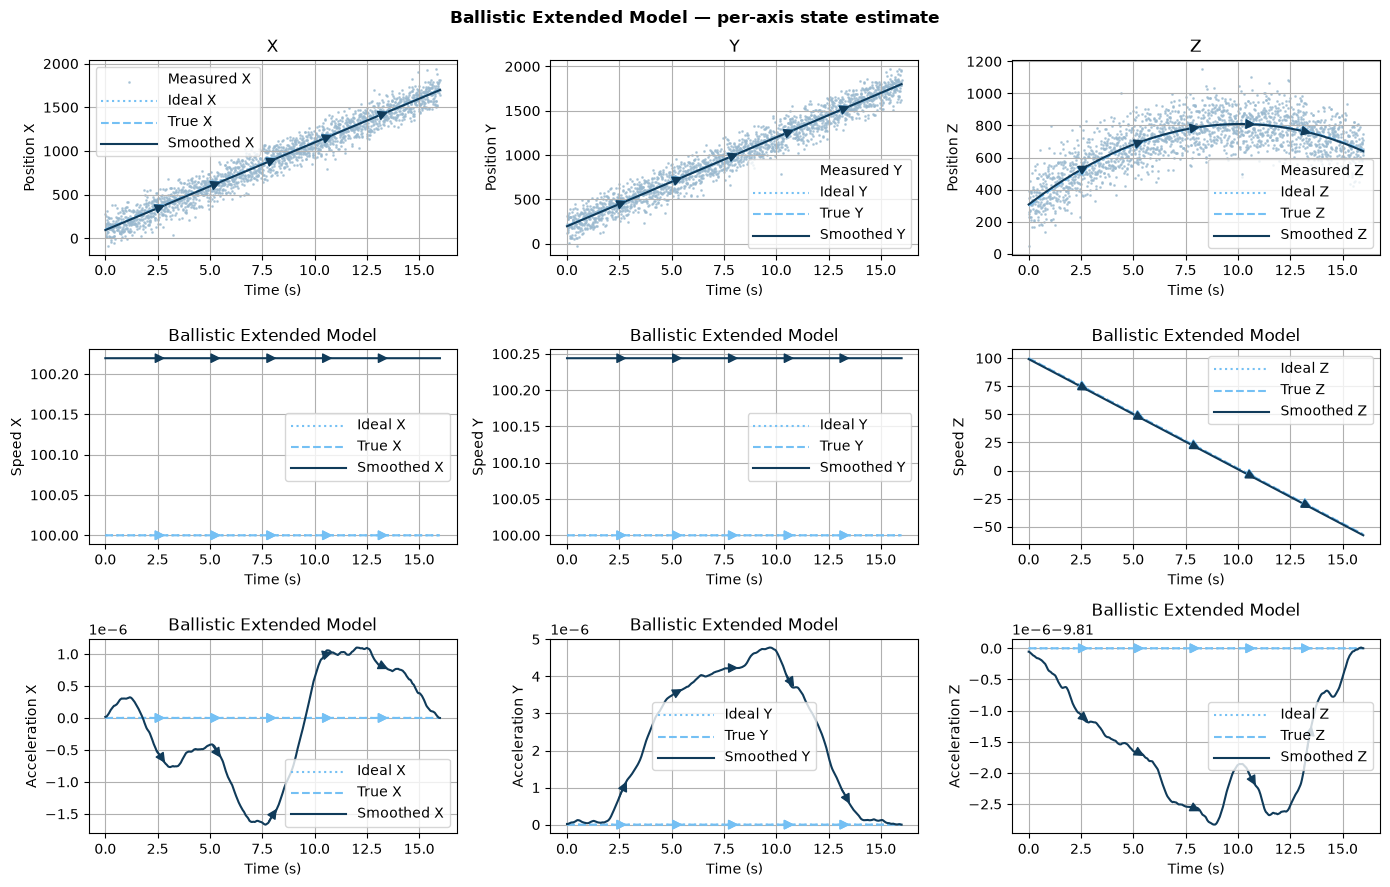

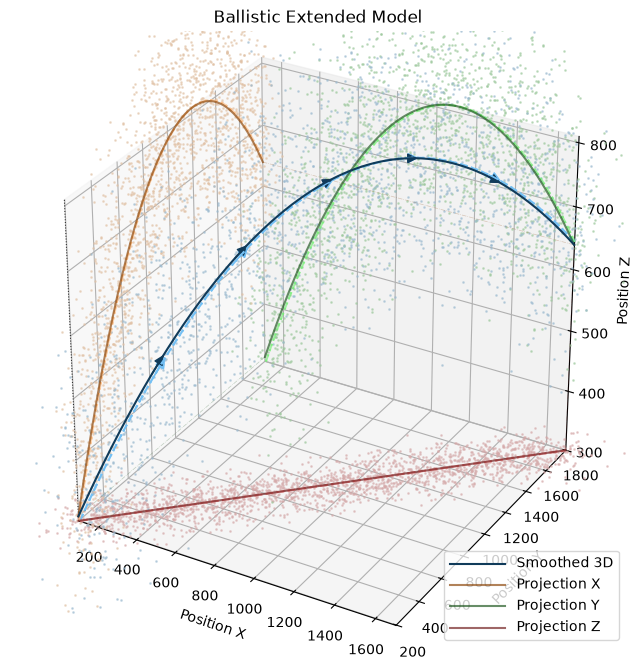

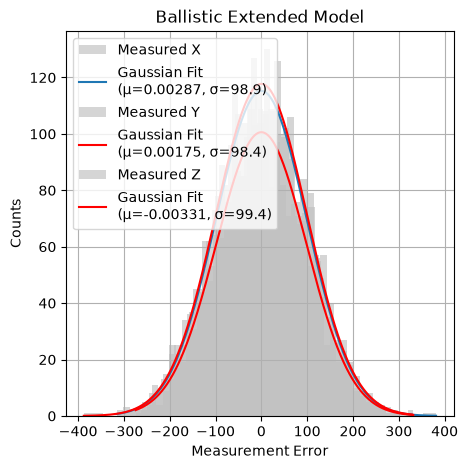

In [6]:
chrono.restart()

from kalman.apps.ballistics import BallisticModel

bulletbill = BallisticModel("XYZ", order=3, fs=128,
                            measurement_uncertainty=100,
                            process_uncertainty=0.5,
                            random_seed=42)

# Axis-major initial state: each row = [pos, vel, acc] for one spatial axis
bulletbill.initial_state([
    [100, 100,     0],    # X: [px, vx, ax]
    [200, 100,     0],    # Y: [py, vy, ay]
    [300, 100, -9.81],    # Z: [pz, vz, az]
])
bulletbill.print()
chrono.lap("Model initialized")

sample = bulletbill.sample(16)
chrono.lap("Sampling completed")

record = bulletbill.filter(sample.zk, smooth=True, reset=True)
chrono.lap("Filtering completed")

# Signature figure: per-axis (position / speed / acceleration) state grid.
bulletbill.plot(record, sample=sample)
chrono.lap("State grid plotted")

# 3D trajectory + measurement-error histogram (record-level one-liners).
record.plot(sample=sample, component="position", view="3d")
record.plot_error(sample=sample)
chrono.lap("3D + error plotted")

chrono.summary()

### EKF vs linear model: what changes?

- **Velocity estimate** — EKF couples the drag effect across axes; when the projectile slows in Z due to drag, the effect propagates to X and Y via the shared $\|\mathbf{v}\|$ term.
- **Acceleration estimate** — the recovered acceleration converges toward the true gravitational + drag acceleration rather than a fitted linear trend.
- **Covariance** — the EKF covariance is propagated through the Jacobian; it correctly accounts for the local nonlinearity of the dynamics at each timestep.
- **3D trajectory** — shows the full parabolic arc; useful for visualising sensor coverage and geometric constraints.

## Possible Improvements & Extensions

### 1. Add a Doppler radar sensor (multi-modal EKF)
A Doppler radar measures **radial velocity** $\dot{r} = \mathbf{v} \cdot \hat{\mathbf{r}}$ — a nonlinear function of the state.  
Adding this as a second measurement channel improves velocity observability without requiring a second position sensor.  
Implementation: subclass `BallisticModel`, override `h()` to return `[px, py, pz, vrad]` and update `H` with its Jacobian.

### 2. Estimate drag coefficient as an augmented state
Make `c_drag` a state variable that evolves as a random walk:
```
ċ_drag = w_drag   (white noise process)
```
Augment the state to `[px,vx,ax, py,vy,ay, pz,vz,az, c_drag]` (10-D).  
The EKF will adaptively estimate drag from the deceleration pattern — useful when the aerodynamic properties of the projectile are uncertain.

### 3. Unscented Kalman Filter (UKF)
The EKF uses a first-order (Jacobian) approximation to propagate uncertainty through nonlinear dynamics.  
The UKF uses a set of sigma points to capture the second-order statistics — more accurate for highly nonlinear systems at a modest computational cost.  
The `kalman` framework provides `KalmanUnscentedFilter` as a drop-in replacement for `KalmanFilter`.

### 4. Multi-sensor fusion (sensor fusion with NaN masking)
If sensors have different update rates (e.g. GPS at 10 Hz, IMU at 1000 Hz), use `NaN` rows in the measurement array.  
The filter skips the update step for NaN rows and performs a prediction-only step — maintaining state continuity between measurements.  
See `04_Suspension.ipynb` for a worked multi-rate example.

## Section 5 — Multi-modal EKF: Position + Doppler Radial Velocity

### Motivation — observability
With a **position-only** sensor, velocity is only *weakly observable*: the filter infers it from the
*change* in position between steps, so the velocity estimate lags and stays noisy. A **Doppler radar**
removes that weakness by measuring velocity almost directly.

**Key terms**
- **Observability** — how well a quantity can be inferred from the available measurements. Adding a
  sensor that responds to velocity makes velocity *strongly* observable.
- **Radial velocity** $\dot r=\mathbf v\cdot\hat{\mathbf r}$ — the velocity component *along the line
  of sight* from the radar; this is exactly what a Doppler shift measures.
- **Multi-modal fusion (sensor fusion)** — combining sensors of different types (here position +
  velocity) inside one filter.

The Doppler term is **nonlinear** (it mixes position and velocity), so it needs the EKF. We subclass
`BallisticModel`, override `h()` to append $\dot r$, and let the framework compute the Jacobian
$H=\partial h/\partial\mathbf x$ numerically:

$$\mathbf z=[p_x,p_y,p_z,\dot r]^\top+\mathbf v,\qquad
R=\mathrm{diag}(r_\text{pos}^2,r_\text{pos}^2,r_\text{pos}^2,r_\text{vel}^2).$$

*What to look for:* the velocity error drops sharply once the Doppler channel is added, versus
position-only tracking.

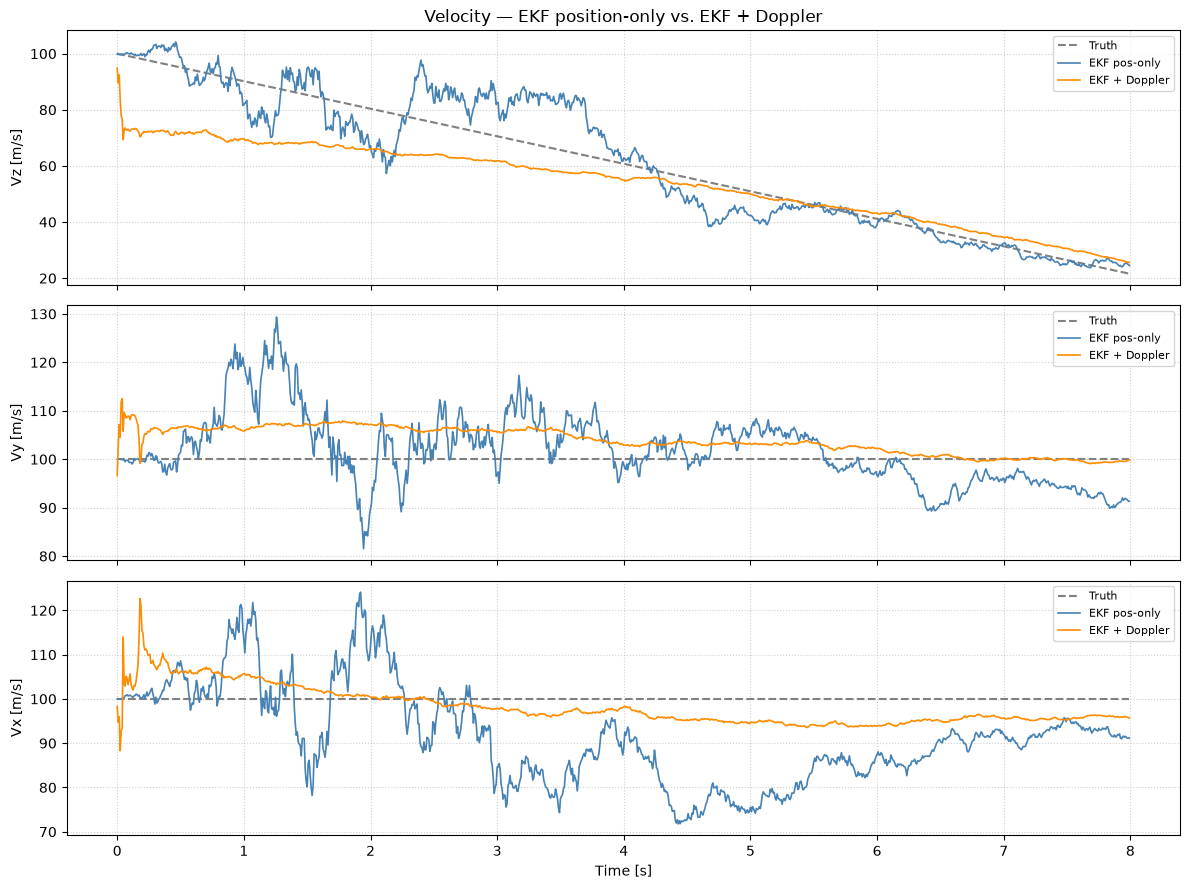

Vx RMS  —  pos-only:  13.78 m/s   pos+Doppler:   4.59 m/s
Vy RMS  —  pos-only:   7.59 m/s   pos+Doppler:   4.78 m/s
Vz RMS  —  pos-only:   8.39 m/s   pos+Doppler:  11.69 m/s
Chrono summary:
 1. EKF pos-only done: 1.129364s (ΔT=1.129364s)
 2. EKF pos+Doppler done: 2.271488s (ΔT=1.142124s)

==> Total elapsed: 2.394307s



In [7]:
import numpy as np
import matplotlib.pyplot as plt
from kalman.apps.ballistics import BallisticModel
from kalman.framework.filter import KalmanFilter
import kalman.runtime.chrono as chrono

# -----------------------------------------------------------------------
# BallisticDopplerModel: extends BallisticModel with radial-velocity obs.
#
# Design note: h() is patched as an INSTANCE ATTRIBUTE after super().__init__()
# so that _check_shapes (called during parent init) still sees the original
# 3-D measurement model.  Once the patch is applied and the engine re-attached,
# the 4-D Doppler h is used for all filtering.
# -----------------------------------------------------------------------
class BallisticDopplerModel(BallisticModel):
    """4D measurement: [px, py, pz, vrad] where vrad = v · (p/|p|)."""

    def __init__(self, *args, vel_noise=5.0, **kwargs):
        # 1. Build the 9D ballistic model (m=3, R=3×3 — passes _check_shapes)
        super().__init__(*args, **kwargs)

        # 2. Expand R to 4×4 and update m
        old_R = self._R.copy()
        new_R = np.zeros((4, 4), dtype=self.dtype)
        new_R[:3, :3] = old_R
        new_R[3, 3]   = float(vel_noise) ** 2
        self._R = new_R
        self.m  = 4

        # 3. Patch h as an instance attribute so the framework uses Doppler h
        dtype = self.dtype
        def _doppler_h(x, v=None, t=None):
            x = np.asarray(x, dtype=dtype).reshape(-1)
            p   = x[[0, 3, 6]]
            vel = x[[1, 4, 7]]
            r   = float(np.linalg.norm(p))
            r_hat = p / r if r > 1.0 else np.array([0., 0., 1.], dtype=dtype)
            vrad  = float(vel @ r_hat)
            z = np.zeros((4, 1), dtype=dtype)
            z[:3, 0] = p
            z[3,  0] = vrad
            if v is not None:
                z += np.asarray(v, dtype=dtype).reshape(4, 1)
            return z

        self.h = _doppler_h          # instance attr shadows the class method

        # 4. Re-attach engine so it sees m=4, R=4×4, and the new h

# -----------------------------------------------------------------------
# Build and run both models on the SAME truth trajectory
# -----------------------------------------------------------------------
chrono.restart()

INIT = [[100, 100, 0], [200, 100, 0], [300, 100, -9.81]]
FS   = 128
T    = 8
SEED = 7

# --- Position-only EKF (baseline) ---
ekf_pos = BallisticModel("XYZ", order=3, fs=FS,
                         measurement_uncertainty=500,
                         process_uncertainty=0.5,
                         random_seed=SEED)
ekf_pos.initial_state(INIT)
sample_pos = ekf_pos.sample(T)
rec_pos    = ekf_pos.filter(sample_pos.zk, smooth=False, reset=True)
chrono.lap("EKF pos-only done")

# --- Position + Doppler EKF ---
ekf_dop = BallisticDopplerModel("XYZ", order=3, fs=FS,
                                measurement_uncertainty=500,
                                process_uncertainty=0.5,
                                vel_noise=2.0,
                                random_seed=SEED)
ekf_dop.initial_state(INIT)
sample_dop = ekf_dop.sample(T)
rec_dop    = ekf_dop.filter(sample_dop.zk, smooth=False, reset=True)
chrono.lap("EKF pos+Doppler done")

# -----------------------------------------------------------------------
# Compare velocity estimates (per axis)
# -----------------------------------------------------------------------
t  = sample_pos.time

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].set_title("Velocity — EKF position-only vs. EKF + Doppler")

for ax, dim, lbl in zip(axes, [7, 4, 1], ["Vz [m/s]", "Vy [m/s]", "Vx [m/s]"]):
    ax.plot(t, sample_pos.xk[:, dim], '--', color='gray',      lw=1.5, label='Truth')
    ax.plot(t, rec_pos.xk[:, dim],    '-',  color='steelblue', lw=1.2, label='EKF pos-only')
    ax.plot(t, rec_dop.xk[:, dim],    '-',  color='darkorange', lw=1.2, label='EKF + Doppler')
    ax.set_ylabel(lbl)
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.6)

axes[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

# RMS velocity error comparison
for lbl, dim in [("Vx", 1), ("Vy", 4), ("Vz", 7)]:
    truth = sample_pos.xk[:, dim]
    rms_p = np.sqrt(np.mean((rec_pos.xk[:, dim] - truth)**2))
    rms_d = np.sqrt(np.mean((rec_dop.xk[:, dim] - truth)**2))
    print(f"{lbl} RMS  —  pos-only: {rms_p:6.2f} m/s   pos+Doppler: {rms_d:6.2f} m/s")

chrono.summary()

## Section 6 — Augmented State: Adaptive Drag Estimation

So far every physical parameter (mass, drag, gravity) was *known* and *fixed*. Reality is messier: a
vehicle's **drag coefficient** changes with shape, attitude, air density and Mach number, and is
often poorly known before flight. A filter using the wrong drag will systematically mis-predict the
trajectory. The remedy is one of the most powerful ideas in estimation — **let the filter learn the
unknown parameter online, while it tracks.**

**Key terms**
- **Parameter estimation** — estimating a *constant of the model* (here $c_\text{drag}$), not just
  the moving state.
- **State augmentation** — append the unknown parameter to the state vector and estimate it jointly
  with position/velocity. The covariance then captures the **correlation** between the parameter and
  the motion — and that correlation is precisely what lets trajectory measurements inform the
  parameter.
- **Random-walk model** — we don't know how $c_\text{drag}$ evolves, so we model it as a slowly
  drifting constant, $\dot c_\text{drag}=w_c$ with small variance $\sigma_c^2$. Small $\sigma_c$ ⇒
  "almost constant"; larger $\sigma_c$ ⇒ "allowed to adapt faster" (but noisier).
- **Observability of a parameter** — a parameter can be estimated only if it leaves a *fingerprint*
  in the measurements. Drag is observable here because it produces a characteristic **deceleration
  pattern** that the position track reveals.

**The augmented model.**
$$\mathbf{x}_{\text{aug}}=\begin{bmatrix}\mathbf{x}_{9D}\\ c_\text{drag}\end{bmatrix}\in\mathbb{R}^{10},
\qquad \dot c_\text{drag}=w_c\sim\mathcal N(0,\sigma_c^2).$$
Because $c_\text{drag}$ enters the dynamics **nonlinearly**, this is naturally an **EKF** problem: the
Jacobian gains an extra row/column coupling the parameter to the velocity states.

**Experiment.**
1. **Truth** — `BallisticModel` flown with real drag `c_drag = 0.005`.
2. **Naive filter** — an EKF that wrongly assumes `c_drag = 0` (drag ignored).
3. **Adaptive filter** — `BallisticAugmentedModel` starts at `c_drag = 0` and *estimates* it.

*What to look for:* the adaptive filter's drag estimate converges toward 0.005 and its position error
stays small, while the naive zero-drag filter drifts as un-modelled drag accumulates.

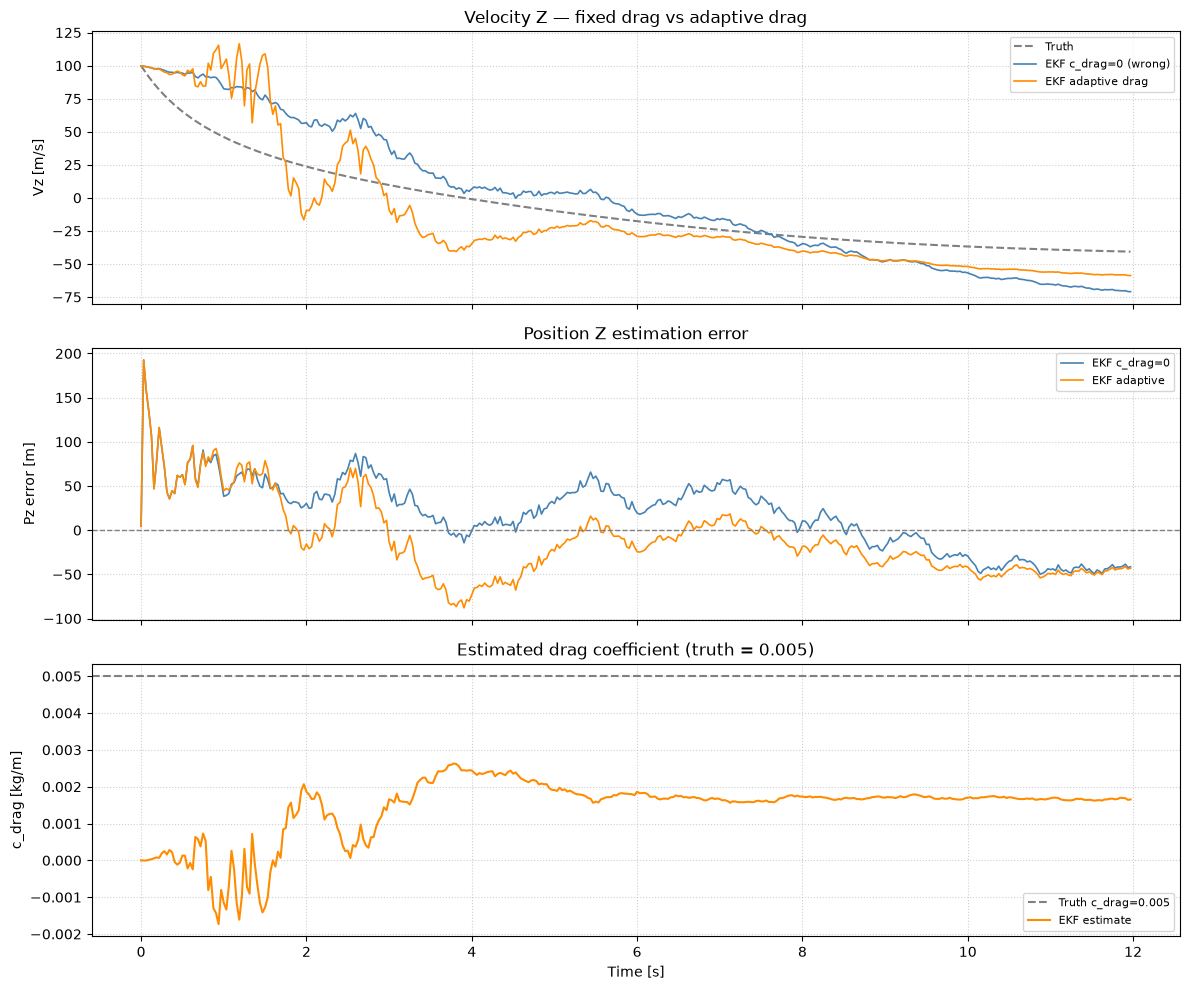

Pz RMS error — EKF fixed drag=0: 43.6 m  |  EKF adaptive: 45.1 m
Estimated c_drag at end: 0.00165  (truth: 0.005)
Chrono summary:
 1. Truth sampled: 0.199005s (ΔT=0.199005s)
 2. EKF fixed drag=0 done: 0.425968s (ΔT=0.226963s)
 3. EKF augmented drag done: 0.688179s (ΔT=0.262211s)

==> Total elapsed: 0.832743s



In [8]:
import numpy as np
import matplotlib.pyplot as plt
from kalman.apps.ballistics import BallisticModel
from kalman.framework.filter import KalmanFilter
import kalman.runtime.chrono as chrono

# -----------------------------------------------------------------------
# BallisticAugmentedModel: 10D state [x9D, c_drag]
#
# Design notes:
# 1. f() and h() are patched as INSTANCE ATTRIBUTES after super().__init__()
#    so that _check_shapes (called during parent init) still sees the 9D model.
# 2. initial_state() is overridden to flatten the 3×3 INIT array to 9 elements
#    and then pad to 10D (c_drag=0) before passing to the parent.  The guard
#    `self.n == 10` ensures the override is a no-op during the parent __init__
#    call (when n is still 9).
# -----------------------------------------------------------------------
class BallisticAugmentedModel(BallisticModel):
    """
    Augments the 9D ballistic state with c_drag as a random-walk state (index 9).
    The filter learns c_drag from the observed deceleration pattern.
    """
    def __init__(self, name, *, drag_process_noise=1e-5, drag_initial_uncertainty=5e-3, **kwargs):
        kwargs['c_drag'] = 0.0   # placeholder; at runtime comes from state[9]
        # 1. Build the standard 9D model (passes _check_shapes intact)
        super().__init__(name, **kwargs)

        q_c     = float(drag_process_noise)
        sigma_c = float(drag_initial_uncertainty)

        # 2. Augment state dimension
        self.n = 10

        # 3. Augment Q: 9×9 → 10×10
        Q10 = np.zeros((10, 10), dtype=self.dtype)
        Q10[:9, :9] = self._Q.copy()
        Q10[9,  9]  = q_c ** 2
        self._Q = Q10

        # 4. Augment x0: c_drag starts at 0
        x0 = np.zeros((10, 1), dtype=self.dtype)
        x0[:9] = self.x0
        self.x0 = x0

        # 5. Augment P0: tight initial uncertainty for c_drag
        P0 = np.zeros((10, 10), dtype=self.dtype)
        P0[:9, :9] = self.P0
        P0[9,  9]  = sigma_c ** 2
        self.P0 = P0

        # 6. Capture parent f / h before patching (bound to self)
        _parent_f = BallisticModel.f.__get__(self, type(self))
        _parent_h = BallisticModel.h.__get__(self, type(self))
        _model    = self
        dtype     = self.dtype

        def _aug_f(x, u=None, w=None, t=None):
            x = np.asarray(x, dtype=dtype).reshape(-1, 1)
            old = _model["c_drag"]
            _model["c_drag"] = float(x[9, 0])
            x9 = _parent_f(x[:9], u=u, w=None, t=t)
            _model["c_drag"] = old
            xn = np.zeros((10, 1), dtype=dtype)
            xn[:9] = np.asarray(x9, dtype=dtype).reshape(9, 1)
            xn[9, 0] = float(x[9, 0])    # c_drag random walk: persists + noise
            if w is not None:
                xn += np.asarray(w, dtype=dtype).reshape(10, 1)
            return xn

        def _aug_h(x, v=None, t=None):
            x = np.asarray(x, dtype=dtype).reshape(-1, 1)
            return _parent_h(x[:9], v=v, t=t)

        self.f = _aug_f
        self.h = _aug_h

        # 7. Re-attach engine with updated dims

    def initial_state(self, x0=None, P0=None):
        """Pad a 9-element initial state to 10D (c_drag=0); no-op during parent init."""
        if x0 is not None and getattr(self, 'n', 9) == 10:
            flat = np.asarray(x0, dtype=getattr(self, 'dtype', np.float64)).ravel()
            if flat.size == 9:
                x10 = np.zeros((10, 1), dtype=flat.dtype)
                x10[:9, 0] = flat
                x0 = x10
        super().initial_state(x0=x0, P0=P0)


# -----------------------------------------------------------------------
# 1. Generate truth with c_drag = 0.005 (non-zero drag)
# -----------------------------------------------------------------------
chrono.restart()

C_DRAG_TRUE = 0.005
INIT = [[100, 100, 0], [200, 100, 0], [300, 100, -9.81]]
FS, T, SEED = 32, 12, 42

truth_model = BallisticModel("XYZ", order=3, fs=FS,
                             c_drag=C_DRAG_TRUE,
                             measurement_uncertainty=300,
                             process_uncertainty=0.3,
                             random_seed=SEED)
truth_model.initial_state(INIT)
truth_sample = truth_model.sample(T)
chrono.lap("Truth sampled")

# -----------------------------------------------------------------------
# 2. Filter A: wrong fixed drag (c_drag = 0)
# -----------------------------------------------------------------------
ekf_nodrag = BallisticModel("XYZ", order=3, fs=FS,
                            c_drag=0.0,
                            measurement_uncertainty=300,
                            process_uncertainty=0.3)
ekf_nodrag.initial_state(INIT)
rec_nodrag = ekf_nodrag.filter(truth_sample.zk, smooth=False, reset=True)
chrono.lap("EKF fixed drag=0 done")

# -----------------------------------------------------------------------
# 3. Filter B: augmented model (adaptive c_drag)
# -----------------------------------------------------------------------
ekf_aug = BallisticAugmentedModel("XYZ", order=3, fs=FS,
                                  measurement_uncertainty=300,
                                  process_uncertainty=0.3,
                                  drag_process_noise=1e-5,
                                  drag_initial_uncertainty=5e-3)
ekf_aug.initial_state(INIT)
rec_aug = ekf_aug.filter(truth_sample.zk, smooth=False, reset=True)
chrono.lap("EKF augmented drag done")

# -----------------------------------------------------------------------
# Plot: velocity Z and estimated c_drag
# -----------------------------------------------------------------------
t = truth_sample.time

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].set_title("Velocity Z — fixed drag vs adaptive drag")
axes[0].plot(t, truth_sample.xk[:, 7], '--', color='gray',       lw=1.5, label='Truth')
axes[0].plot(t, rec_nodrag.xk[:, 7],   '-',  color='steelblue',  lw=1.2, label='EKF c_drag=0 (wrong)')
axes[0].plot(t, rec_aug.xk[:, 7],       '-',  color='darkorange', lw=1.2, label='EKF adaptive drag')
axes[0].set_ylabel("Vz [m/s]"); axes[0].legend(fontsize=8); axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].set_title("Position Z estimation error")
axes[1].plot(t, rec_nodrag.xk[:, 6] - truth_sample.xk[:, 6], '-', color='steelblue',  lw=1.2, label='EKF c_drag=0')
axes[1].plot(t, rec_aug.xk[:, 6]    - truth_sample.xk[:, 6], '-', color='darkorange',  lw=1.2, label='EKF adaptive')
axes[1].axhline(0, color='gray', lw=1, linestyle='--')
axes[1].set_ylabel("Pz error [m]"); axes[1].legend(fontsize=8); axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].set_title(f"Estimated drag coefficient (truth = {C_DRAG_TRUE})")
axes[2].axhline(C_DRAG_TRUE, color='gray', lw=1.5, linestyle='--', label=f'Truth c_drag={C_DRAG_TRUE}')
axes[2].plot(t, rec_aug.xk[:, 9], '-', color='darkorange', lw=1.5, label='EKF estimate')
axes[2].set_ylabel("c_drag [kg/m]"); axes[2].set_xlabel("Time [s]")
axes[2].legend(fontsize=8); axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

rms_nd = np.sqrt(np.mean((rec_nodrag.xk[:, 6] - truth_sample.xk[:, 6])**2))
rms_ag = np.sqrt(np.mean((rec_aug.xk[:, 6]    - truth_sample.xk[:, 6])**2))
print(f"Pz RMS error — EKF fixed drag=0: {rms_nd:.1f} m  |  EKF adaptive: {rms_ag:.1f} m")
print(f"Estimated c_drag at end: {rec_aug.xk[-1, 9]:.5f}  (truth: {C_DRAG_TRUE})")
chrono.summary()

## Section 7 — UKF vs EKF Comparison

Both filters handle nonlinearity, but in different ways — and knowing *when each wins* is a core
practical skill.

**Key terms**
- **EKF** — linearises with the first-order **Jacobian** $F=\partial f/\partial\mathbf x$. Exact for
  linear systems; its error grows with the *curvature* of $f$.
- **Unscented transform (UT)** — instead of differentiating, push a small, deterministically chosen
  set of **sigma points** through the *exact* nonlinear function, then recompute their mean and
  covariance.
- **UKF** — applies the UT; it captures effects up to **second order** with **no Jacobian** — you
  supply only $f$ and $h$.

| | EKF | UKF |
|---|---|---|
| Linearisation | first-order Jacobian | sigma-point UT (2nd-order) |
| Needs | a Jacobian (analytic/numeric) | only $f$, $h$ |
| Cost / step | $\mathcal O(n^2)$ | $\mathcal O(n^3)$ (Cholesky) |
| Best when | mild nonlinearity | stronger nonlinearity |

For the near-linear ballistic model the two are comparable; with stronger nonlinearity (steep
elevation, heavy drag) the UKF usually gives tighter, more consistent covariance.

**Usage.** `UnscentedKalmanFilter(model)` wraps the *same* `BallisticModel` — only the **engine** (the
estimation algorithm) changes, not the model — and returns a `KalmanRecord` like every other filter.

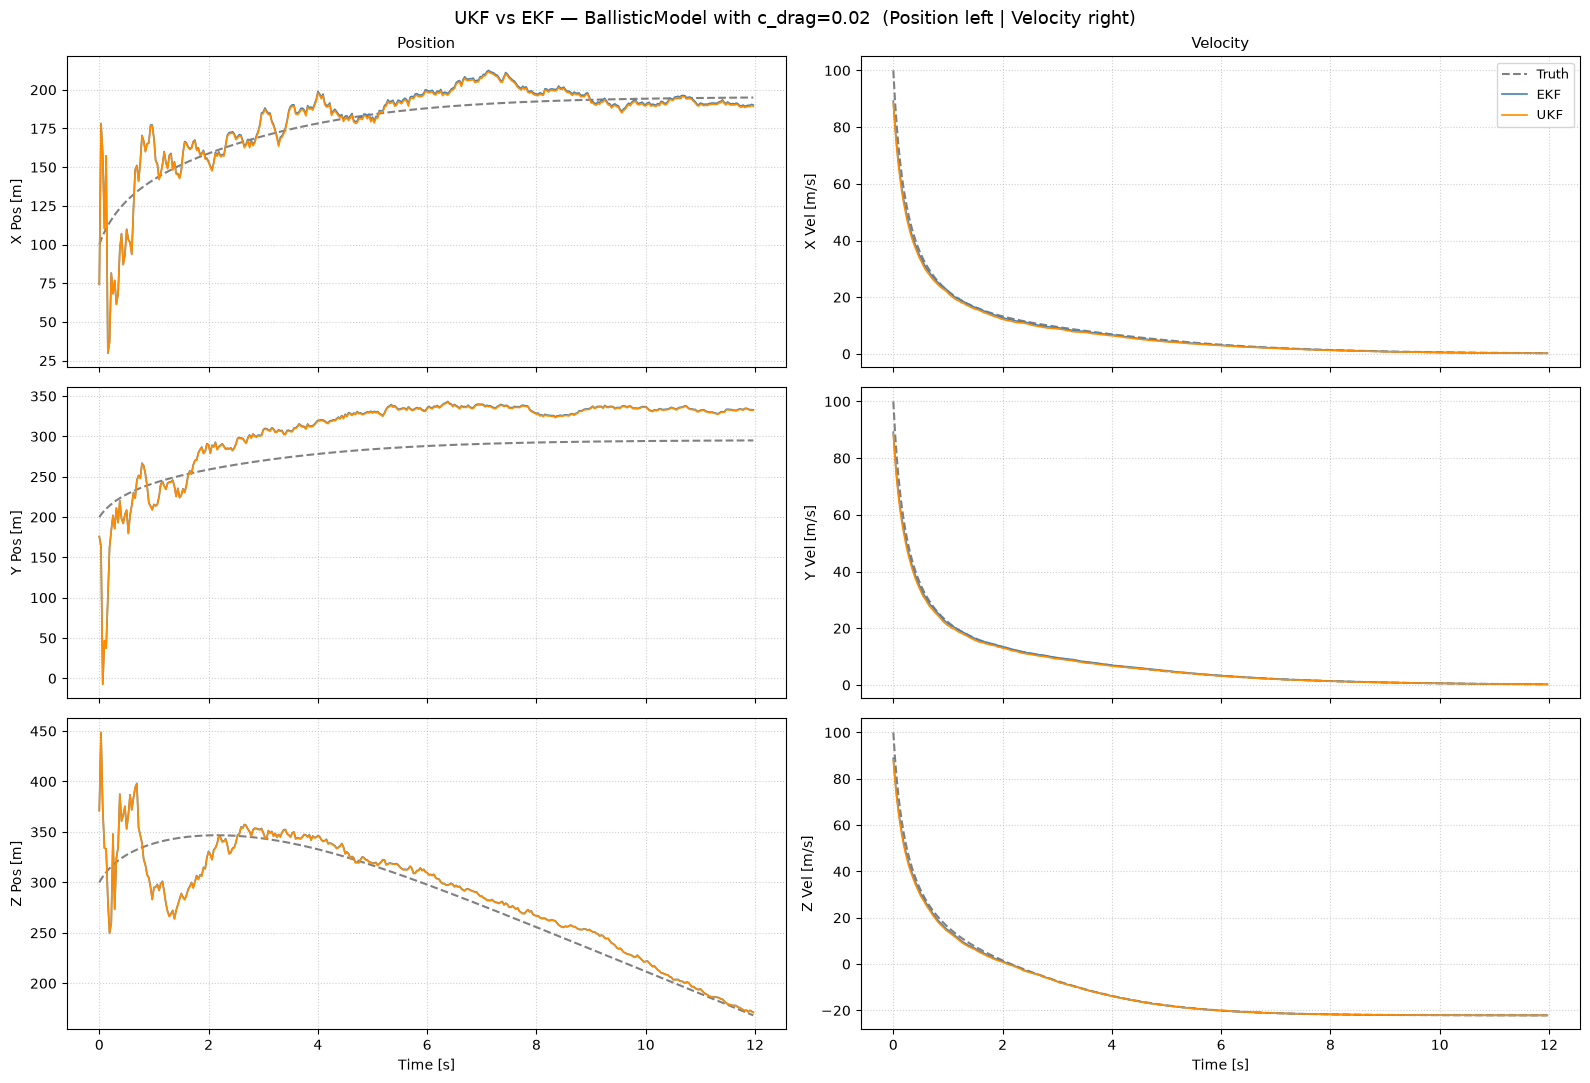

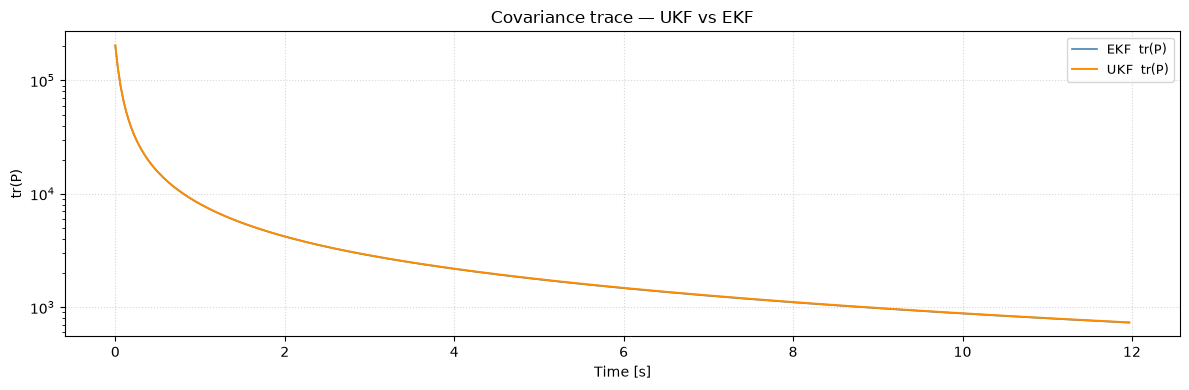

Component               EKF RMS      UKF RMS
--------------------------------------------
Position X                14.16 m     13.91 m
Position Y                42.00 m     41.37 m
Position Z                22.94 m     22.96 m
Velocity X                 1.03 m/s      1.32 m/s
Velocity Y                 1.00 m/s      1.23 m/s
Velocity Z                 1.11 m/s      1.38 m/s
Chrono summary:
 1. Truth sampled: 0.196683s (ΔT=0.196683s)
 2. EKF done: 0.422071s (ΔT=0.225388s)
 3. UKF done: 0.879289s (ΔT=0.457218s)

==> Total elapsed: 1.223362s



In [9]:
import numpy as np
import matplotlib.pyplot as plt
from kalman.apps.ballistics import BallisticModel
from kalman.filters.ukf import UnscentedKalmanFilter
import kalman.runtime.chrono as chrono

chrono.restart()

# -----------------------------------------------------------------------
# Use non-zero drag to expose nonlinearity (UKF advantage over EKF)
# -----------------------------------------------------------------------
C_DRAG_CMP = 0.02     # stronger drag → more nonlinearity
INIT_CMP   = [[100, 100, 0], [200, 100, 0], [300, 100, -9.81]]
FS_CMP, T_CMP, SEED_CMP = 32, 12, 99

truth_cmp = BallisticModel("XYZ", order=3, fs=FS_CMP,
                            c_drag=C_DRAG_CMP,
                            measurement_uncertainty=300,
                            process_uncertainty=0.3,
                            random_seed=SEED_CMP)
truth_cmp.initial_state(INIT_CMP)
sample_cmp = truth_cmp.sample(T_CMP)
chrono.lap("Truth sampled")

# -----------------------------------------------------------------------
# EKF  — standard framework filter (linearises via Jacobian)
# -----------------------------------------------------------------------
ekf_cmp = BallisticModel("XYZ", order=3, fs=FS_CMP,
                          c_drag=C_DRAG_CMP,
                          measurement_uncertainty=300,
                          process_uncertainty=0.3)
ekf_cmp.initial_state(INIT_CMP)
rec_ekf = ekf_cmp.filter(sample_cmp.zk, smooth=False, reset=True)
chrono.lap("EKF done")

# -----------------------------------------------------------------------
# UKF  — UnscentedKalmanFilter from kalman.filters.ukf
#         returns (xk, Pk) raw arrays (N, n) and (N, n, n)
# -----------------------------------------------------------------------
ukf_model = BallisticModel("XYZ", order=3, fs=FS_CMP,
                            c_drag=C_DRAG_CMP,
                            measurement_uncertainty=300,
                            process_uncertainty=0.3)
ukf_model.initial_state(INIT_CMP)

ukf = UnscentedKalmanFilter(ukf_model, alpha=1e-3, beta=2.0, kappa=0.0)
rec_ukf = ukf.filter(sample_cmp.zk, reset=True)
xk_ukf, Pk_ukf = rec_ukf.xk, rec_ukf.Pk
chrono.lap("UKF done")

# -----------------------------------------------------------------------
# Column-wise plot: rows = X / Y / Z, cols = Position | Velocity
# -----------------------------------------------------------------------
t_cmp       = sample_cmp.time
axes_labels = ["X", "Y", "Z"]
idx_pos     = [0, 3, 6]
idx_vel     = [1, 4, 7]

fig, axes = plt.subplots(3, 2, figsize=(16, 11), sharex=True)
fig.suptitle(
    f"UKF vs EKF — BallisticModel with c_drag={C_DRAG_CMP}  "
    f"(Position left | Velocity right)",
    fontsize=13)

for row, (lbl, pos_dim, vel_dim) in enumerate(zip(axes_labels, idx_pos, idx_vel)):
    for col, (dim, unit, comp) in enumerate([(pos_dim, "m", "Pos"), (vel_dim, "m/s", "Vel")]):
        ax = axes[row, col]
        truth = sample_cmp.xk[:, dim]
        ax.plot(t_cmp, truth,                '--', color='gray',       lw=1.5, label='Truth')
        ax.plot(t_cmp, rec_ekf.xk[:, dim],  '-',  color='steelblue',  lw=1.2, label='EKF')
        ax.plot(t_cmp, xk_ukf[:, dim],      '-',  color='darkorange', lw=1.2, label='UKF')
        ax.set_ylabel(f"{lbl} {comp} [{unit}]")
        ax.grid(True, linestyle=':', alpha=0.6)
        if row == 0:
            ax.set_title(f"{'Position' if col == 0 else 'Velocity'}", fontsize=11)
        if row == 0 and col == 1:
            ax.legend(loc='upper right', fontsize=9)

axes[-1, 0].set_xlabel("Time [s]")
axes[-1, 1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------
# Covariance trace: UKF vs EKF
# -----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
ax.semilogy(t_cmp, np.trace(rec_ekf.Pk, axis1=1, axis2=2),
            '-', color='steelblue',  lw=1.2, label='EKF  tr(P)')
ax.semilogy(t_cmp, np.trace(Pk_ukf,    axis1=1, axis2=2),
            '-', color='darkorange', lw=1.4, label='UKF  tr(P)')
ax.set_xlabel("Time [s]"); ax.set_ylabel("tr(P)")
ax.set_title("Covariance trace — UKF vs EKF")
ax.legend(fontsize=9); ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout(); plt.show()

# -----------------------------------------------------------------------
# RMS error summary
# -----------------------------------------------------------------------
print(f"{'Component':<18} {'EKF RMS':>12} {'UKF RMS':>12}")
print("-" * 44)
for name, indices, unit in [("Position", idx_pos, "m"), ("Velocity", idx_vel, "m/s")]:
    for i, dim in enumerate(indices):
        truth  = sample_cmp.xk[:, dim]
        rms_e  = np.sqrt(np.mean((rec_ekf.xk[:, dim] - truth) ** 2))
        rms_u  = np.sqrt(np.mean((xk_ukf[:, dim]     - truth) ** 2))
        print(f"{name} {axes_labels[i]:<12}  {rms_e:>8.2f} {unit}  {rms_u:>8.2f} {unit}")

chrono.summary()


## Section 8 — Multi-rate Sensor Fusion (GPS at 10 Hz in a 128 Hz loop)

### Motivation
Different sensors run at different rates. A GPS fix arrives at **10 Hz**, but the projectile's state
changes on a **millisecond** scale. Filtering only at 10 Hz leaves 100 ms gaps with no state
propagation — drift accumulates and fast events between fixes are invisible.

**Key terms**
- **Multi-rate fusion** — predict at the *fast* base rate, and update whenever *any* sensor delivers
  data.
- **Prediction-only step** — between measurements the filter runs just the predict stage: it advances
  the state and **grows** the covariance, honestly reflecting the rising uncertainty.
- **NaN masking** — the framework's convention for "no measurement this step": a `NaN` row in `zk`
  triggers a predict-only step (the engine skips the update for the missing channels).

Run the loop at **128 Hz** and inject GPS only when it fires:
```
t = 0   ms   GPS fires  → predict + update   ([px, py, pz])
t = 7.8 ms   GPS silent → predict only       ([nan, nan, nan])
t = 100 ms   GPS fires  → predict + update
```
`make_multirate_input([(z_gps, 10.0)], base_fs=128)` builds the NaN-padded matrix automatically.

| Filter | rate | notes |
|---|---|---|
| 128 Hz baseline | 128 Hz | oracle (a measurement every step) |
| 10 Hz naive | 10 Hz | GPS only, no inter-sample propagation |
| Multi-rate | 128 Hz predict / 10 Hz update | best of both |

*What to look for:* the multi-rate filter matches the high-rate oracle between GPS pulses, while the
10 Hz-only filter drifts in the gaps.

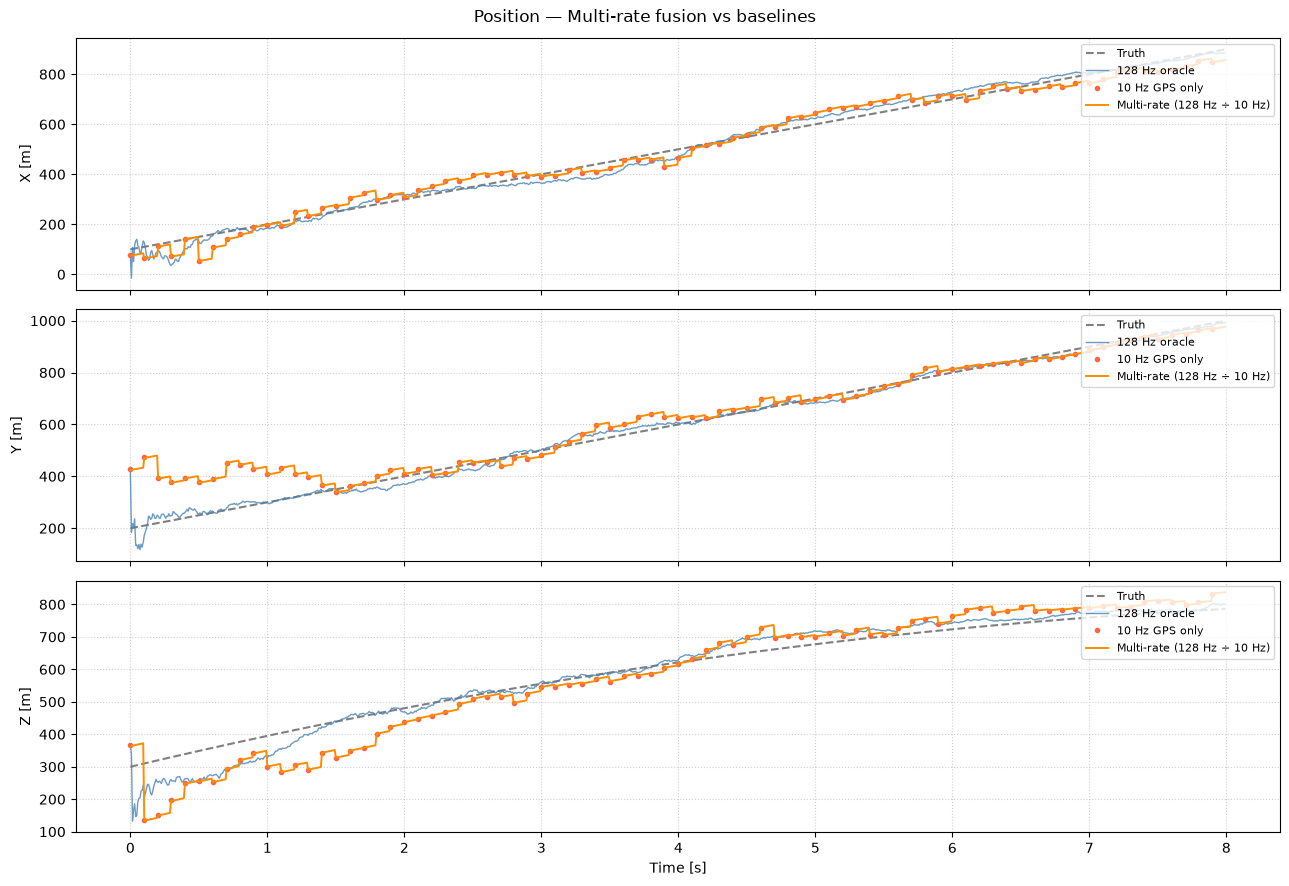

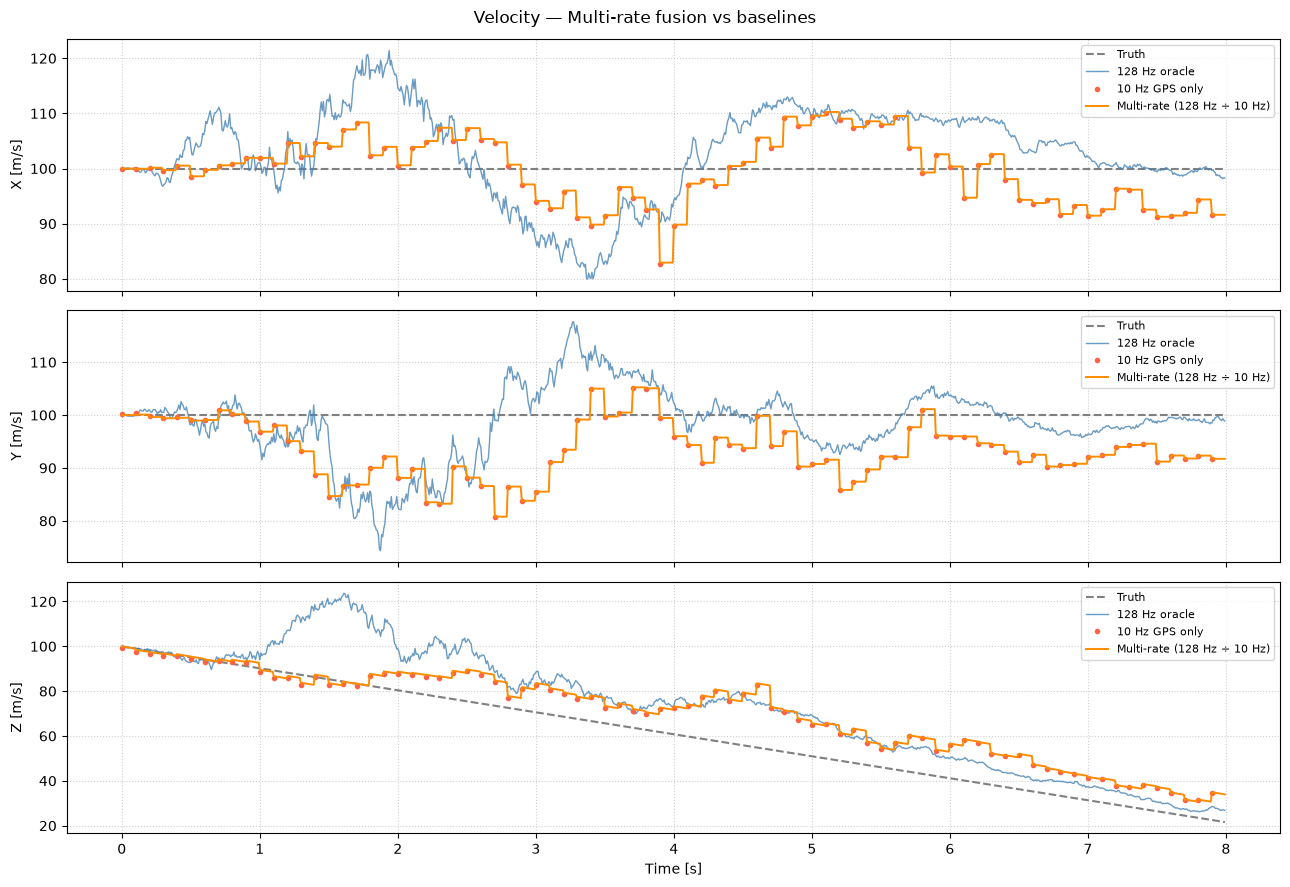

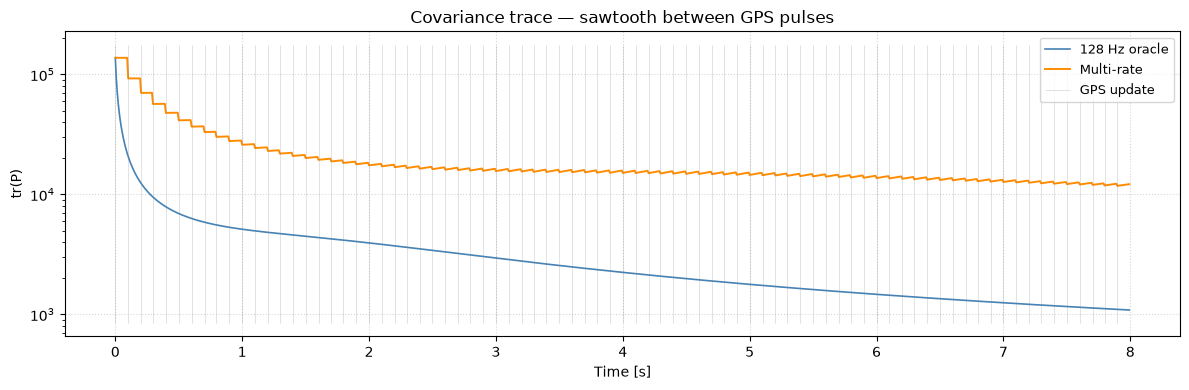

Position X:  128 Hz=  25.58 m  |  GPS only=  30.69 m  |  Multi-rate=  32.19 m
Position Y:  128 Hz=  18.76 m  |  GPS only=  66.40 m  |  Multi-rate=  68.40 m
Position Z:  128 Hz=  34.72 m  |  GPS only=  57.38 m  |  Multi-rate=  59.48 m
Velocity X:  128 Hz=   8.75 m/s  |  GPS only=   5.92 m/s  |  Multi-rate=   6.02 m/s
Velocity Y:  128 Hz=   6.93 m/s  |  GPS only=   8.33 m/s  |  Multi-rate=   8.35 m/s
Velocity Z:  128 Hz=  15.19 m/s  |  GPS only=  11.35 m/s  |  Multi-rate=  11.82 m/s
Chrono summary:
 1. Sampling done: 0.518312s (ΔT=0.518312s)
 2. 128 Hz baseline done: 1.123730s (ΔT=0.605418s)
 3. 10 Hz naive GPS done: 1.172851s (ΔT=0.049121s)
 4. Multi-rate done: 1.703535s (ΔT=0.530684s)

==> Total elapsed: 2.020175s



In [10]:
import numpy as np
import matplotlib.pyplot as plt
from kalman.apps.ballistics import BallisticModel
from kalman.helpers import make_multirate_input
import kalman.runtime.chrono as chrono

chrono.restart()

# -----------------------------------------------------------------------
# Configuration
# -----------------------------------------------------------------------
FS_BASE   = 128.0   # base (prediction) rate [Hz]
FS_GPS    = 10.0    # GPS update rate [Hz]
T         = 8.0     # simulation duration [s]
SEED      = 17
INIT      = [[100, 100, 0], [200, 100, 0], [300, 100, -9.81]]

# -----------------------------------------------------------------------
# Model at base rate
# -----------------------------------------------------------------------
model = BallisticModel("XYZ", order=3, fs=FS_BASE,
                       measurement_uncertainty=300,
                       process_uncertainty=0.5,
                       random_seed=SEED)
model.initial_state(INIT)

# -----------------------------------------------------------------------
# Truth + full-rate measurements (oracle baseline)
# -----------------------------------------------------------------------
sample = model.sample(T)
N_base = len(sample.zk)                           # = T * FS_BASE = 1024
chrono.lap("Sampling done")

# -----------------------------------------------------------------------
# A: 128 Hz filter — oracle baseline (all measurements available)
# -----------------------------------------------------------------------
rec_full = model.filter(sample.zk, smooth=False, reset=True)
chrono.lap("128 Hz baseline done")

# -----------------------------------------------------------------------
# B: GPS-only at 10 Hz — naive: subsample measurements, filter at 10 Hz
# Use exactly int(T*FS_GPS) GPS samples so make_multirate_input outputs
# exactly N_base rows when passed to the multi-rate filter.
# -----------------------------------------------------------------------
model_10 = BallisticModel("XYZ", order=3, fs=FS_GPS,
                          measurement_uncertainty=300,
                          process_uncertainty=0.5)
model_10.initial_state(INIT)

# GPS fires at times 0, 1/FS_GPS, 2/FS_GPS, ... → map to nearest base index
n_gps     = int(T * FS_GPS)                       # = 80
gps_idx   = np.clip(
    np.round(np.arange(n_gps) * FS_BASE / FS_GPS).astype(int),
    0, N_base - 1
)
z_gps_only = sample.zk[gps_idx]                   # (80, 3) — exactly T*FS_GPS rows
t_gps      = sample.time[gps_idx]
rec_gps    = model_10.filter(z_gps_only, smooth=False, reset=True)
chrono.lap("10 Hz naive GPS done")

# -----------------------------------------------------------------------
# C: Multi-rate — 128 Hz predict, 10 Hz update
# make_multirate_input: duration = 80/10 = 8.0 s → N_base = 1024 rows ✓
# -----------------------------------------------------------------------
z_multirate = make_multirate_input([(z_gps_only, FS_GPS)], base_fs=FS_BASE)
assert len(z_multirate) == N_base, f"Expected {N_base} rows, got {len(z_multirate)}"
rec_mr = model.filter(z_multirate, smooth=False, reset=True)
chrono.lap("Multi-rate done")

# -----------------------------------------------------------------------
# Plot: position and velocity across all three filters
# -----------------------------------------------------------------------
t_full     = sample.time
axes_labels = ["X", "Y", "Z"]
idx_pos     = [0, 3, 6]
idx_vel     = [1, 4, 7]

for component, indices, unit in [("Position", idx_pos, "m"),
                                  ("Velocity", idx_vel, "m/s")]:
    fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
    fig.suptitle(f"{component} — Multi-rate fusion vs baselines", fontsize=12)
    for ax, dim, lbl in zip(axes, indices, axes_labels):
        truth = sample.xk[:, dim]
        ax.plot(t_full, truth,                   '--', color='gray',       lw=1.5, label='Truth')
        ax.plot(t_full, rec_full.xk[:, dim],     '-',  color='steelblue',  lw=1.0, alpha=0.8, label='128 Hz oracle')
        ax.plot(t_gps,  rec_gps.xk[:, dim],      'o',  color='tomato',     ms=3,   label=f'{FS_GPS:.0f} Hz GPS only')
        ax.plot(t_full, rec_mr.xk[:, dim],       '-',  color='darkorange', lw=1.4, label='Multi-rate (128 Hz ÷ 10 Hz)')
        ax.set_ylabel(f"{lbl} [{unit}]")
        ax.legend(loc='upper right', fontsize=8)
        ax.grid(True, linestyle=':', alpha=0.6)
    axes[-1].set_xlabel("Time [s]")
    plt.tight_layout()
    plt.show()

# -----------------------------------------------------------------------
# Covariance trace over time: multi-rate vs oracle
# -----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
trace_full = np.trace(rec_full.Pk, axis1=1, axis2=2)
trace_mr   = np.trace(rec_mr.Pk,   axis1=1, axis2=2)
ax.semilogy(t_full, trace_full, '-', color='steelblue',  lw=1.2, label='128 Hz oracle')
ax.semilogy(t_full, trace_mr,   '-', color='darkorange', lw=1.4, label='Multi-rate')
# Mark GPS fire times
gps_times = t_full[~np.isnan(z_multirate[:, 0])]
ylim = ax.get_ylim()
ax.vlines(gps_times, ylim[0], ylim[1], color='gray', lw=0.4, alpha=0.4, label='GPS update')
ax.set_xlabel("Time [s]"); ax.set_ylabel("tr(P)")
ax.set_title("Covariance trace — sawtooth between GPS pulses")
ax.legend(fontsize=9); ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout(); plt.show()

# -----------------------------------------------------------------------
# RMS error summary
# -----------------------------------------------------------------------
for name, indices, unit in [("Position", idx_pos, "m"), ("Velocity", idx_vel, "m/s")]:
    for i, dim in enumerate(indices):
        truth  = sample.xk[:, dim]
        rms_f  = np.sqrt(np.mean((rec_full.xk[:, dim] - truth)**2))
        rms_mr = np.sqrt(np.mean((rec_mr.xk[:, dim]   - truth)**2))
        # Interpolate 10 Hz GPS record to full-rate grid for fair comparison
        xk_gps_interp = np.interp(t_full, t_gps, rec_gps.xk[:, dim])
        rms_g  = np.sqrt(np.mean((xk_gps_interp - truth)**2))
        print(f"{name} {axes_labels[i]}:  "
              f"128 Hz={rms_f:7.2f} {unit}  |  "
              f"GPS only={rms_g:7.2f} {unit}  |  "
              f"Multi-rate={rms_mr:7.2f} {unit}")

chrono.summary()